# Survival Analysis for Delivery Time-to-Event

## Goal
Predict **when** a package gets delivered, not just whether it is late.

We will implement:
- **Kaplan-Meier** curves (delivery probability over time)
- **Cox Proportional Hazards** model (which factors speed up or slow down delivery)

## Survival Basics (Simple)
- **Duration**: days from order approval to delivery (or censor date)
- **Event**: delivery happened (`event_observed = 1`)
- **Censored**: delivery not observed yet (`event_observed = 0`)

In [3]:
# If this fails, run once and restart kernel:
%pip install lifelines

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [4]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

try:
    from lifelines import KaplanMeierFitter, CoxPHFitter
    LIFELINES_AVAILABLE = True
except ImportError:
    LIFELINES_AVAILABLE = False

sns.set_theme(style='whitegrid')
print('lifelines available:', LIFELINES_AVAILABLE)
if not LIFELINES_AVAILABLE:
    raise ImportError('lifelines is not installed. Run: %pip install lifelines')

lifelines available: True


## Step 1: Load Data

In [5]:
try:
    df = pd.read_csv('../../datasets/processed/olist_reviews_with_preds.csv')
    print('Loaded: olist_reviews_with_preds.csv')
except FileNotFoundError:
    df = pd.read_csv('../../datasets/processed/olist_reviews_rich.csv')
    print('Loaded: olist_reviews_rich.csv')

print('Raw shape:', df.shape)
display(df.head(3))

Loaded: olist_reviews_with_preds.csv
Raw shape: (94009, 45)


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,review_score,seller_id,...,estimated_delivery_days,delivery_delay_days,is_late,seller_total_orders,log_price,log_distance,freight_ratio,late_delay,price_x_delay,expected_review_A
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,4.0,3504c0cb71d7fa48d967e0e4c94d59d9,...,15,-7.0,0,52.0,3.433665,2.979690,0.281381,-0.0,-24.035652,4.284404
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,4.0,289cdb325fb7e7f891c38608bf9e0962,...,19,-6.0,0,105.0,4.784989,6.759296,0.190142,-0.0,-28.709932,4.395447
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,5.0,4869f7a5dfa277a7dca6462dcf3b52b2,...,26,-17.0,0,1117.0,5.080783,6.245229,0.119453,-0.0,-86.373312,4.489018


## Step 2: Build Survival Dataset
We create `duration_days` and `event_observed`.

- Start time: `order_approved_at`
- End time: `order_delivered_customer_date` if available
- If not delivered, we censor at a reference date

In [6]:
date_cols = [
    'order_purchase_timestamp',
    'order_approved_at',
    'order_delivered_carrier_date',
    'order_delivered_customer_date',
    'order_estimated_delivery_date'
]
for c in date_cols:
    if c in df.columns:
        df[c] = pd.to_datetime(df[c], errors='coerce')

if 'order_approved_at' not in df.columns:
    raise ValueError('order_approved_at is required for survival analysis.')

ref_candidates = []
for c in ['order_delivered_customer_date', 'order_estimated_delivery_date', 'order_purchase_timestamp']:
    if c in df.columns and df[c].notna().any():
        ref_candidates.append(df[c].max())

reference_date = max(ref_candidates) if len(ref_candidates) > 0 else pd.Timestamp.today().normalize()
print('Reference date for censoring:', reference_date)

surv = df.copy()
surv = surv[surv['order_approved_at'].notna()].copy()

surv['event_observed'] = surv['order_delivered_customer_date'].notna().astype(int)
surv['end_date'] = surv['order_delivered_customer_date'].fillna(reference_date)
surv['duration_days'] = (surv['end_date'] - surv['order_approved_at']).dt.total_seconds() / 86400.0

# Keep only valid durations
surv = surv[surv['duration_days'].notna()].copy()
surv = surv[surv['duration_days'] >= 0].copy()
surv['duration_days'] = surv['duration_days'].clip(lower=0.1)

print('Survival dataset shape:', surv.shape)
print('Observed deliveries:', int(surv['event_observed'].sum()))
print('Censored orders:', int((1 - surv['event_observed']).sum()))
display(surv[['duration_days', 'event_observed']].head())

Reference date for censoring: 2018-10-25 00:00:00
Survival dataset shape: (93937, 48)
Observed deliveries: 93937
Censored orders: 0


,duration_days,event_observed
0,8.429144,1
1,12.502292,1
2,9.382708,1
3,13.196331,1
4,2.830938,1


## Step 3: Kaplan-Meier (Overall)
This curve shows the probability a package is **still not delivered** by day *t*.

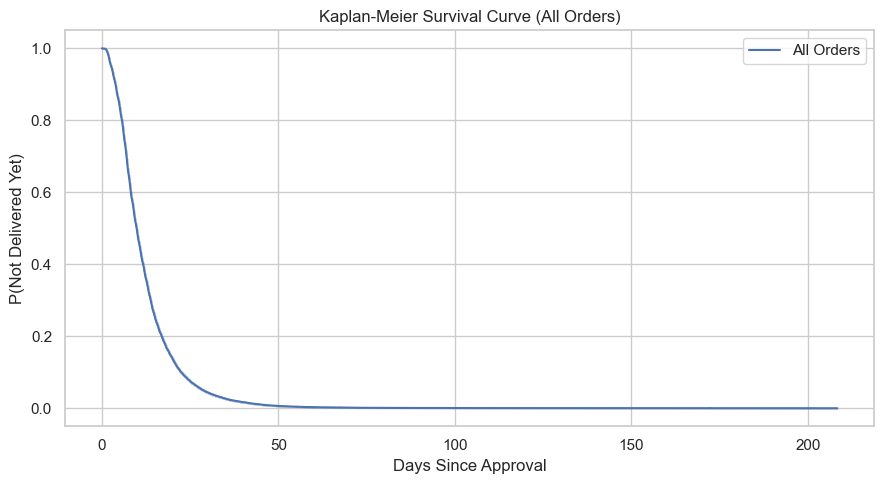

Median delivery time (days): 9.83


In [7]:
kmf = KaplanMeierFitter()
kmf.fit(durations=surv['duration_days'], event_observed=surv['event_observed'], label='All Orders')

plt.figure(figsize=(9, 5))
kmf.plot_survival_function(ci_show=True)
plt.title('Kaplan-Meier Survival Curve (All Orders)')
plt.xlabel('Days Since Approval')
plt.ylabel('P(Not Delivered Yet)')
plt.tight_layout()
plt.show()

print('Median delivery time (days):', round(float(kmf.median_survival_time_), 2))

## Step 4: Kaplan-Meier by Distance Group
We compare short-distance vs long-distance routes.

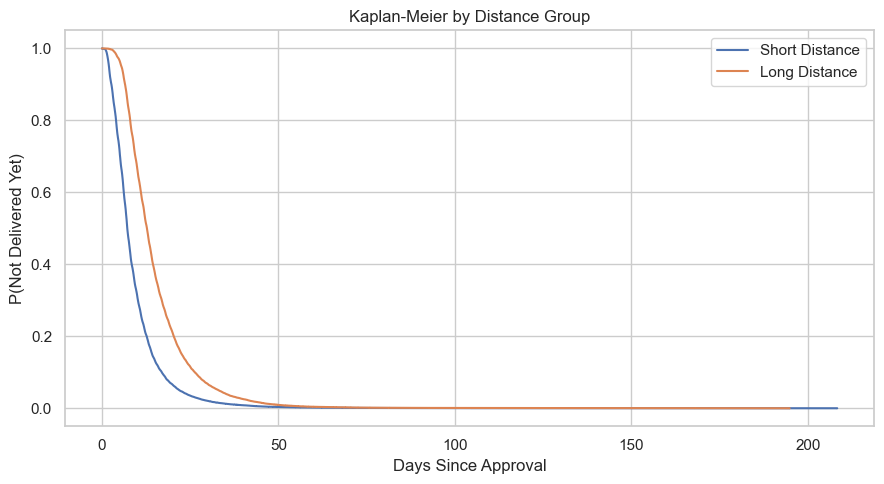

Distance median cutoff (km): 434.5


In [8]:
if 'distance_km' not in surv.columns:
    raise ValueError('distance_km is required for distance-group survival curves.')

distance_cutoff = surv['distance_km'].median()
surv['long_distance'] = (surv['distance_km'] >= distance_cutoff).astype(int)

plt.figure(figsize=(9, 5))
for val, label in [(0, 'Short Distance'), (1, 'Long Distance')]:
    part = surv[surv['long_distance'] == val]
    km_group = KaplanMeierFitter()
    km_group.fit(part['duration_days'], event_observed=part['event_observed'], label=label)
    km_group.plot_survival_function(ci_show=False)

plt.title('Kaplan-Meier by Distance Group')
plt.xlabel('Days Since Approval')
plt.ylabel('P(Not Delivered Yet)')
plt.tight_layout()
plt.show()

print('Distance median cutoff (km):', round(float(distance_cutoff), 2))

## Step 5: Cox Proportional Hazards Model
Now we estimate how each feature changes delivery hazard.

Important interpretation:
- Hazard Ratio (HR) > 1: faster delivery (higher chance of delivery at each time point)
- Hazard Ratio (HR) < 1: slower delivery

In [9]:
# Feature engineering for Cox
if 'customer_state' in surv.columns and 'seller_state' in surv.columns:
    surv['is_cross_state'] = (surv['customer_state'] != surv['seller_state']).astype(int)
else:
    surv['is_cross_state'] = 0

candidate_covariates = [
    'distance_km',
    'product_weight_g',
    'price',
    'freight_value',
    'n_items',
    'seller_total_orders',
    'is_cross_state'
]
covariates = [c for c in candidate_covariates if c in surv.columns]

cox_df = surv[['duration_days', 'event_observed'] + covariates].copy()
for c in covariates:
    cox_df[c] = pd.to_numeric(cox_df[c], errors='coerce')
    cox_df[c] = cox_df[c].fillna(cox_df[c].median())

# mild clipping to reduce extreme outlier impact
for c in ['distance_km', 'price', 'freight_value', 'product_weight_g']:
    if c in cox_df.columns:
        lo, hi = cox_df[c].quantile([0.01, 0.99])
        cox_df[c] = cox_df[c].clip(lo, hi)

cph = CoxPHFitter()
cph.fit(cox_df, duration_col='duration_days', event_col='event_observed')

summary_cols = ['coef', 'exp(coef)', 'p']
summary_table = cph.summary[summary_cols].sort_values('exp(coef)')
display(summary_table)

print('Covariates used in Cox model:', covariates)

,coef,exp(coef),p
covariate,,,
is_cross_state,-0.725600,0.484034,0.000000e+00
distance_km,-0.000451,0.999549,0.000000e+00
seller_total_orders,-0.000102,0.999898,6.830867e-48
price,-0.000059,0.999941,1.701554e-02
product_weight_g,-0.000034,0.999966,1.603249e-152
freight_value,0.001342,1.001343,1.983840e-04
n_items,0.017014,1.017159,2.038824e-02


Covariates used in Cox model: ['distance_km', 'product_weight_g', 'price', 'freight_value', 'n_items', 'seller_total_orders', 'is_cross_state']


## Step 6: Plain-English Interpretation
We convert statistical output into business language.

In [10]:
hr = cph.summary[['exp(coef)', 'p']].copy()
hr = hr.rename(columns={'exp(coef)': 'hazard_ratio'})
sig = hr[hr['p'] < 0.05].sort_values('hazard_ratio')

print('Significant effects (p < 0.05):')
if len(sig) == 0:
    print('No covariate is statistically significant at p < 0.05 in this run.')
else:
    display(sig)

    for feature, row in sig.iterrows():
        h = float(row['hazard_ratio'])
        if h > 1:
            print(f'- {feature}: HR={h:.3f} -> tends to speed up delivery.')
        else:
            print(f'- {feature}: HR={h:.3f} -> tends to slow down delivery.')

Significant effects (p < 0.05):


,hazard_ratio,p
covariate,,
is_cross_state,0.484034,0.000000e+00
distance_km,0.999549,0.000000e+00
seller_total_orders,0.999898,6.830867e-48
price,0.999941,1.701554e-02
product_weight_g,0.999966,1.603249e-152
freight_value,1.001343,1.983840e-04
n_items,1.017159,2.038824e-02


- is_cross_state: HR=0.484 -> tends to slow down delivery.
- distance_km: HR=1.000 -> tends to slow down delivery.
- seller_total_orders: HR=1.000 -> tends to slow down delivery.
- price: HR=1.000 -> tends to slow down delivery.
- product_weight_g: HR=1.000 -> tends to slow down delivery.
- freight_value: HR=1.001 -> tends to speed up delivery.
- n_items: HR=1.017 -> tends to speed up delivery.


## Step 7: Example Curves from Cox Model
Compare two representative orders (shorter vs longer route) using predicted survival curves.

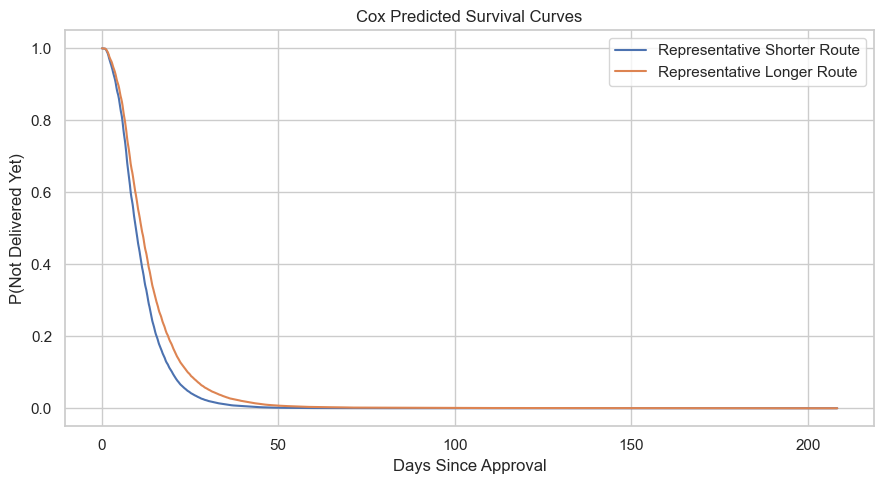

In [11]:
med = cox_df[covariates].median()
low_distance = cox_df['distance_km'].quantile(0.25) if 'distance_km' in covariates else None
high_distance = cox_df['distance_km'].quantile(0.75) if 'distance_km' in covariates else None

profile_short = med.copy()
profile_long = med.copy()
if 'distance_km' in covariates:
    profile_short['distance_km'] = low_distance
    profile_long['distance_km'] = high_distance

pred_short = cph.predict_survival_function(profile_short.to_frame().T)
pred_long = cph.predict_survival_function(profile_long.to_frame().T)

plt.figure(figsize=(9, 5))
plt.plot(pred_short.index, pred_short.iloc[:, 0], label='Representative Shorter Route')
plt.plot(pred_long.index, pred_long.iloc[:, 0], label='Representative Longer Route')
plt.title('Cox Predicted Survival Curves')
plt.xlabel('Days Since Approval')
plt.ylabel('P(Not Delivered Yet)')
plt.legend()
plt.tight_layout()
plt.show()

## Step 8: Optional Assumption Check
Cox relies on proportional hazards assumptions. Run this only if you want a deeper diagnostic.

In [13]:
# This may print many lines. Uncomment if needed:
cph.check_assumptions(cox_df, p_value_threshold=0.05, show_plots=False)
# print('Assumption check is optional and currently skipped for cleaner beginner workflow.')

The ``p_value_threshold`` is set at 0.05. Even under the null hypothesis of no violations, some
covariates will be below the threshold by chance. This is compounded when there are many covariates.
Similarly, when there are lots of observations, even minor deviances from the proportional hazard
assumption will be flagged.

With that in mind, it's best to use a combination of statistical tests and visual tests to determine
the most serious violations. Produce visual plots using ``check_assumptions(..., show_plots=True)``
and looking for non-constant lines. See link [A] below for a full example.





1. Variable 'distance_km' failed the non-proportional test: p-value is <5e-05.

   Advice 1: the functional form of the variable 'distance_km' might be incorrect. That is, there
may be non-linear terms missing. The proportional hazard test used is very sensitive to incorrect
functional forms. See documentation in link [D] below on how to specify a functional form.

   Advice 2: try binning the variable 'distance_km' using pd.cut, and then specify it in
`strata=['distance_km', ...]` in the call in `.fit`. See documentation in link [B] below.

   Advice 3: try adding an interaction term with your time variable. See documentation in link [C]
below.


2. Variable 'product_weight_g' failed the non-proportional test: p-value is <5e-05.

   Advice 1: the functional form of the variable 'product_weight_g' might be incorrect. That is,
there may be non-linear terms missing. The proportional hazard test used is very sensitive to
incorrect functional forms. See documentation in link [D] below on

[]

## Final Business Takeaway
- Kaplan-Meier tells us delivery timing risk over days.
- Cox model quantifies which variables accelerate or delay delivery.
- This is stronger operational insight than simple late/not-late classification because it supports SLA planning and proactive interventions.